In [1]:

import msprime
import pandas as pd
import csv
import numpy as np

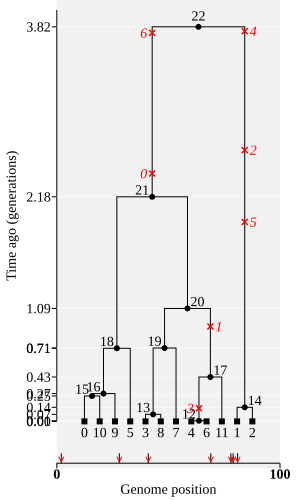

In [102]:
ts = msprime.sim_ancestry(6, sequence_length=100, random_seed=1234)
mts = msprime.sim_mutations(ts, rate=0.004, random_seed=5678)
mts.draw_svg(y_axis=True, y_gridlines=True, size=(300, 500))



In [99]:
i = 0
df_mut = pd.DataFrame(columns=["Site_ID", "Mutation_ID", "fixed", "Inherited_State", "Derived_State", "Mutation_Age", "tMRCA", "Human_Carriers"])
for site in mts.sites():
    tree = mts.at(site.position)
    for mut in site.mutations:
        carriers = set(tree.samples(mut.node))
        for mut_2 in site.mutations:
            if mut_2.parent == mut.id:
                carriers -= set(tree.samples(mut_2.node))
        if len(carriers)>1:
            tmrca = tree.tmrca(*carriers)
        else:
            tmrca = 0
        fixed = len(carriers) == len(set(ts.samples()))
        df_mut.loc[i] = [site.id, mut.id, fixed, mut.inherited_state, mut.derived_state, mut.time, tmrca, carriers]
        i += 1
df_mut

,Site_ID,Mutation_ID,fixed,Inherited_State,Derived_State,Mutation_Age,tMRCA,Human_Carriers
0,0,0,False,G,T,0.909307,0.708411,"{0, 9, 10, 5}"
1,1,1,False,C,G,2.285035,2.176263,"{0, 3, 4, 5, 6, 7, 8, 9, 10, 11}"
2,2,2,False,A,C,0.940558,0.430153,"{11, 4, 6}"
3,3,3,False,G,A,1.275899,0.136755,"{1, 2}"
4,4,4,False,C,G,2.420045,0.136755,"{1, 2}"
5,5,5,False,C,A,1.150569,0.136755,"{1, 2}"
6,6,6,False,C,G,2.461911,0.136755,"{1, 2}"
7,7,7,False,C,A,0.853642,0.430153,"{11, 4, 6}"
8,8,8,False,T,C,3.574198,0.136755,"{1, 2}"
9,9,9,False,A,G,1.866021,0.708411,"{0, 9, 10, 5}"


In [104]:
i = 0
df_var = pd.DataFrame(columns=["Site_ID", "Position", "Site_Alleles", "Human_Genotypes"])
for var in mts.variants():
    human_genotypes = var.genotypes
    df_var.loc[i] = [var.site.id, var.site.position, var.alleles, human_genotypes]
    i += 1
df_var

,Site_ID,Position,Site_Alleles,Human_Genotypes
0,0,2.0,"(A, G)","[1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1]"
1,1,28.0,"(C, T)","[0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1]"
2,2,41.0,"(C, T)","[0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
3,3,69.0,"(T, A)","[0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0]"
4,4,78.0,"(A, C)","[0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
5,5,79.0,"(C, G)","[0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
6,6,81.0,"(T, G)","[1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1]"


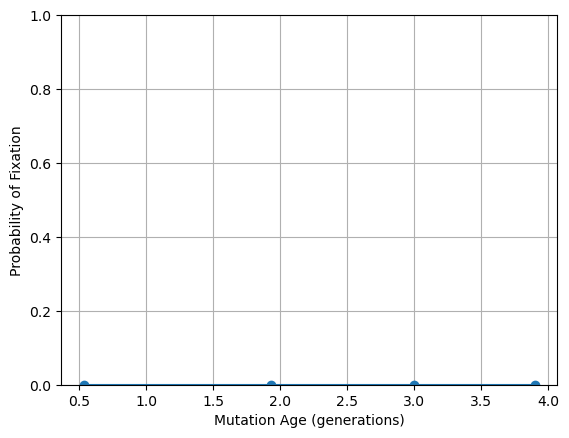

In [ ]:
import matplotlib.pyplot as plt

l = df_mut["Mutation_Age"].tolist()
s = pd.qcut(l, q=4)
d_fixed = {interval: [] for interval in s.categories}
d_age = {interval: [] for interval in s.categories}

for i in range(len(l)):
    d_fixed[s[i]].append(df_mut["fixed"].tolist()[i])
    d_age[s[i]].append(df_mut["Mutation_Age"].tolist()[i])


x = []
y = []

for interval in d_fixed.keys():
    x.append(np.mean(d_age[interval]))
    y.append(np.mean(d_fixed[interval]))

plt.plot(x, y, marker="o")
plt.xlabel("Mutation Age (generations)")
plt.ylabel("Probability of Fixation")
plt.ylim(0, 1)
plt.grid(True)
plt.show()